# 04 — Prédiction de la résilience Charpy

Deuxième facette de la qualité : la **ténacité**, c'est-à-dire la capacité de la soudure à
absorber un choc sans rompre brutalement. On applique la même démarche qu'au notebook 03
(même nettoyage, mêmes modèles, même validation croisée imbriquée groupée par publication).

Plan :
1. Particularités des données Charpy
2. Formulation du problème
3. Modèles et validation
4. Résultats
5. Courbes de transition prédites
6. Et le semi-supervisé ?
7. Conclusion

In [1]:
import os
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

sys.path.insert(0, str(Path.cwd().parent / "src"))
import preprocessing
import welddb

sns.set_theme(style="whitegrid", context="notebook")
warnings.filterwarnings("ignore", message=".*sklearn.utils.parallel.delayed.*")
os.environ["PYTHONWARNINGS"] = "ignore:`sklearn.utils.parallel.delayed`:UserWarning"  # processus parallèles
TARGET = "charpy_toughness_J"
TEMP = "charpy_temp_C"
RESULTS = Path.cwd().parent / "results"
RESULTS.mkdir(exist_ok=True)

## 1. Particularités des données Charpy

L'essai Charpy mesure l'énergie (en joules) absorbée par une éprouvette entaillée frappée
par un pendule, **à une température donnée**. L'acier passe d'un comportement ductile
(beaucoup d'énergie absorbée) à chaud à un comportement fragile (peu d'énergie) à froid :
c'est la **transition ductile-fragile**.

In [2]:
df = welddb.load()
labelled = df[df[TARGET].notna()].reset_index(drop=True)
print(f"{len(labelled)} lignes avec un essai Charpy, {labelled['publication'].nunique()} publications")
print(f"Température d'essai toujours renseignée : {labelled[TEMP].notna().all()}")
print("\nValeurs d'énergie les plus fréquentes :")
print(labelled[TARGET].value_counts().head(5).to_string())

879 lignes avec un essai Charpy, 26 publications
Température d'essai toujours renseignée : True

Valeurs d'énergie les plus fréquentes :
charpy_toughness_J
100.0    356
28.0     118
50.0      16
35.0      12
70.0      12


**Une particularité importante** : 356 lignes valent exactement **100 J** et 118 valent
**28 J**, presque toutes issues des travaux d'Evans. Dans ces publications, l'énergie est
fixée et c'est la **température** qui est mesurée : « à quelle température la soudure
absorbe-t-elle 100 J (ou 28 J) ? ». Ces températures de transition sont un critère courant
pour comparer des soudures.

type de mesure
énergie fixée (100 / 28 J)    474
énergie mesurée               405


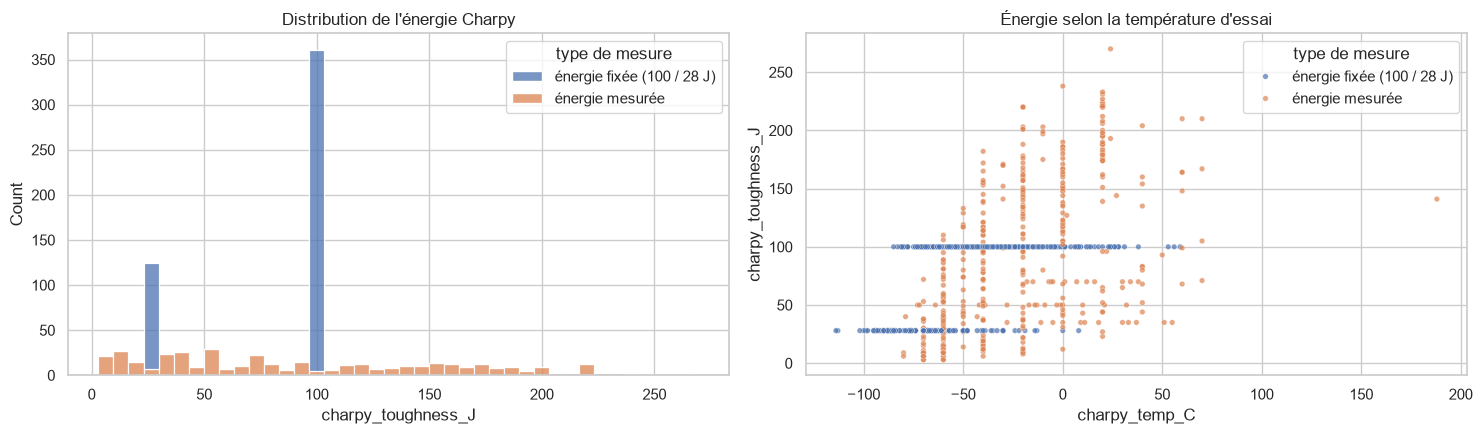

In [3]:
iso = labelled[TARGET].isin([100, 28])
labelled["type de mesure"] = np.where(iso, "énergie fixée (100 / 28 J)", "énergie mesurée")
print(labelled["type de mesure"].value_counts().to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(data=labelled, x=TARGET, hue="type de mesure", bins=40, multiple="stack", ax=axes[0])
axes[0].set_title("Distribution de l'énergie Charpy")
sns.scatterplot(data=labelled, x=TEMP, y=TARGET, hue="type de mesure", s=16, alpha=0.7, ax=axes[1])
axes[1].set_title("Énergie selon la température d'essai")
plt.tight_layout();

Les deux types de lignes décrivent la même chose : des points (température, énergie) sur la
courbe de transition d'une soudure. Une ligne « 100 J à −28 °C » signifie que la courbe passe
par 100 J à −28 °C. On peut donc les garder toutes, à condition de mettre la température en
entrée du modèle.

## 2. Formulation du problème

**Cible** : énergie Charpy (J). **Entrées** : la recette (les mêmes 25 variables qu'au
notebook 03) **plus la température d'essai**. Le modèle apprend ainsi toute la courbe de
transition, et on peut lui demander « combien de joules à −40 °C ? », qui est la question
pratique pour une structure travaillant au froid.

*Alternative écartée* : prédire la température de transition (à 100 J ou 28 J) à partir de
la recette. Elle ne pourrait utiliser que les 474 lignes « énergie fixée » (18
publications), et perdrait les autres.

**Référence supplémentaire** : en plus de la moyenne, une forêt aléatoire qui ne connaît
**que la température d'essai**. Elle mesure ce que la recette apporte réellement : un modèle
utile doit faire mieux qu'elle.

In [4]:
X = preprocessing.clean(labelled, extra=[TEMP])
y = labelled[TARGET].to_numpy()
groups = labelled["publication"].to_numpy()
print(f"Entrées : {X.shape[1]} variables, dont la température d'essai")

Entrées : 26 variables, dont la température d'essai


## 3. Modèles et validation

Même protocole qu'au notebook 03 : validation croisée externe `GroupKFold` (5 plis par
publication), choix des hyperparamètres par une validation croisée interne groupée (4
plis), mêmes modèles (dont le gradient boosting) et mêmes grilles. Métriques : RMSE (principale), MAE et R², en joules.

In [5]:
def make_model(estimator):
    pipe = Pipeline([("prep", preprocessing.make_preprocessor(extra=[TEMP])), ("model", estimator)])
    return TransformedTargetRegressor(regressor=pipe, transformer=StandardScaler())

P = "regressor__model__"
MODELS = {
    "Moyenne (référence)": (DummyRegressor(), {}),
    "Régression linéaire": (LinearRegression(), {}),
    "k-NN": (KNeighborsRegressor(),
             {P + "n_neighbors": [5, 10, 20, 40, 80], P + "weights": ["uniform", "distance"]}),
    "SVR": (SVR(kernel="rbf"),
            {P + "C": [0.1, 1, 10, 100], P + "gamma": ["scale", 0.01, 0.1], P + "epsilon": [0.05, 0.2]}),
    "Forêt aléatoire": (RandomForestRegressor(n_estimators=300, random_state=0, n_jobs=-1),
                        {P + "max_features": [0.33, 0.66, 1.0], P + "min_samples_leaf": [1, 3, 5]}),
    "Gradient boosting": (GradientBoostingRegressor(n_estimators=300, subsample=0.8, random_state=0),
                          {P + "learning_rate": [0.03, 0.1], P + "max_depth": [2, 3, 5]}),
}
TEMP_ONLY = "Température seule (référence)"

Pour la section 5, on choisit aussi quelques soudures (une par publication) testées à au
moins 5 températures différentes : pour chacune, quand sa publication est dans le pli de test, on fait prédire au
modèle toute la courbe de transition.

In [6]:
# "SvenGret-1990-3Ch-6" -> "SvenGret-1990-3" : on retire le suffixe de l'essai Charpy
labelled["soudure"] = labelled["weld_id"].str.replace(r"(Ch|ch)-?\d*$", "", regex=True)
candidates = labelled[~iso].groupby("soudure").filter(lambda g: g[TEMP].nunique() >= 5)
curve_welds = candidates.drop_duplicates("publication")["soudure"].to_numpy()[:4]  # une par publication
temp_grid = np.linspace(-100, 40, 57)
print("Soudures choisies :", list(curve_welds))

Soudures choisies : ['Evans-StressRelief-1991-0.045A', 'SvenGret-1990-1', 'Chandel&-1985W1']


In [7]:
outer_cv = GroupKFold(n_splits=5)
inner_cv = GroupKFold(n_splits=4)

scores, best_params, curves = [], [], []
oof = {name: np.full(len(y), np.nan) for name in [*MODELS, TEMP_ONLY]}

start = time.time()
for fold, (train, test) in enumerate(outer_cv.split(X, y, groups)):
    for name, (estimator, grid) in MODELS.items():
        model = make_model(estimator)
        if grid:
            search = GridSearchCV(model, grid, cv=inner_cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
            search.fit(X.iloc[train], y[train], groups=groups[train])
            model = search.best_estimator_
            best_params.append({"pli": fold, "modèle": name,
                                **{k.removeprefix(P): v for k, v in search.best_params_.items()}})
        else:
            model.fit(X.iloc[train], y[train])
        oof[name][test] = model.predict(X.iloc[test])

        if name in ("SVR", "Forêt aléatoire", "Gradient boosting"):
            for weld in curve_welds:
                rows = labelled.index[labelled["soudure"] == weld]
                if rows[0] in test:
                    recipe = X.loc[[rows[0]] * len(temp_grid)].assign(**{TEMP: temp_grid})
                    curves.append(pd.DataFrame({"soudure": weld, "modèle": name, TEMP: temp_grid,
                                                TARGET: model.predict(recipe)}))

    temp_only = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=0, n_jobs=-1)
    temp_only.fit(X.iloc[train][[TEMP]], y[train])
    oof[TEMP_ONLY][test] = temp_only.predict(X.iloc[test][[TEMP]])

    for name in oof:
        scores.append({"pli": fold, "modèle": name,
                       "RMSE": root_mean_squared_error(y[test], oof[name][test]),
                       "MAE": mean_absolute_error(y[test], oof[name][test]),
                       "R²": r2_score(y[test], oof[name][test])})
print(f"Durée : {time.time() - start:.0f} s")
scores = pd.DataFrame(scores)
curves = pd.concat(curves)

Durée : 25 s


## 4. Résultats

In [8]:
order = ["Moyenne (référence)", TEMP_ONLY, "Régression linéaire", "k-NN", "SVR", "Forêt aléatoire", "Gradient boosting"]
summary = scores.groupby("modèle")[["RMSE", "MAE", "R²"]].agg(["mean", "std"]).loc[order]
summary.round(2)

RMSE           MAE           R²      
                                mean    std   mean    std  mean   std
modèle                                                               
Moyenne (référence)            51.22   4.28  39.90   3.41 -0.18  0.18
Température seule (référence)  45.05   7.64  33.21   6.17  0.03  0.48
Régression linéaire            67.20  35.78  54.17  31.94 -1.35  2.17
k-NN                           49.13   4.73  37.72   4.07 -0.09  0.21
SVR                            39.69   8.14  30.53   5.75  0.28  0.26
Forêt aléatoire                45.11  10.27  34.24   7.96  0.07  0.39
Gradient boosting              46.59   7.88  34.78   5.77  0.00  0.36

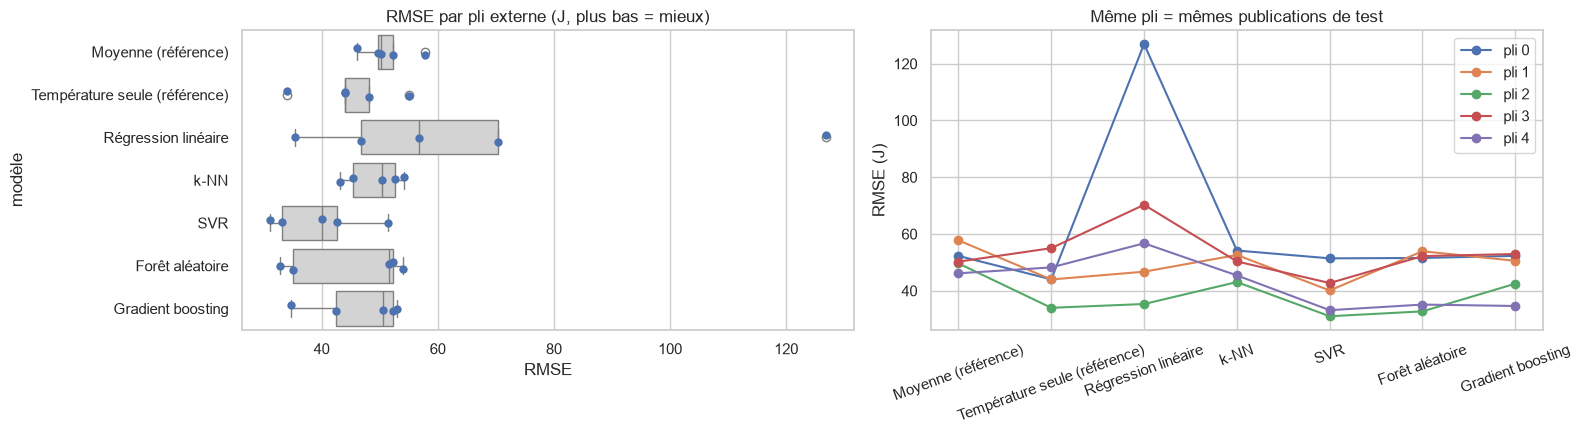

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
sns.boxplot(data=scores, y="modèle", x="RMSE", order=order, ax=axes[0], color="lightgrey")
sns.stripplot(data=scores, y="modèle", x="RMSE", order=order, ax=axes[0], color="C0", size=6)
axes[0].set_title("RMSE par pli externe (J, plus bas = mieux)")

wide = scores.pivot(index="pli", columns="modèle", values="RMSE")[order]
for fold, row in wide.iterrows():
    axes[1].plot(order, row.values, "o-", label=f"pli {fold}")
axes[1].set_ylabel("RMSE (J)"); axes[1].legend(); axes[1].tick_params(axis="x", rotation=20)
axes[1].set_title("Même pli = mêmes publications de test")
plt.tight_layout();

In [10]:
pd.DataFrame(best_params).set_index(["modèle", "pli"]).sort_index()

n_neighbors   weights    C  epsilon  gamma  \
modèle            pli                                               
Forêt aléatoire   0            NaN       NaN  NaN      NaN    NaN   
                  1            NaN       NaN  NaN      NaN    NaN   
                  2            NaN       NaN  NaN      NaN    NaN   
                  3            NaN       NaN  NaN      NaN    NaN   
                  4            NaN       NaN  NaN      NaN    NaN   
Gradient boosting 0            NaN       NaN  NaN      NaN    NaN   
                  1            NaN       NaN  NaN      NaN    NaN   
                  2            NaN       NaN  NaN      NaN    NaN   
                  3            NaN       NaN  NaN      NaN    NaN   
                  4            NaN       NaN  NaN      NaN    NaN   
SVR               0            NaN       NaN  1.0     0.05   0.01   
                  1            NaN       NaN  1.0     0.20   0.01   
                  2            NaN       NaN  1.0     0.05   0.01   
                  3            NaN       NaN  1.0     0.05   0.01   
                  4            NaN       NaN  1.0     0.05   0.01   
k-NN              0           40.0  distance  NaN      NaN    NaN   
                  1           80.0  distance  NaN      NaN    NaN   
                  2           80.0  distance  NaN      NaN    NaN   
                  3           80.0   uniform  NaN      NaN    NaN   
                  4           80.0   uniform  NaN      NaN    NaN   

                       max_features  min_samples_leaf  learning_rate  \
modèle            pli                                                  
Forêt aléatoire   0            0.33               1.0            NaN   
                  1            1.00               1.0            NaN   
                  2            0.33               1.0            NaN   
                  3            0.66               5.0            NaN   
                  4            0.33               1.0            NaN   
Gradient boosting 0             NaN               NaN           0.03   
                  1             NaN               NaN           0.10   
                  2             NaN               NaN           0.10   
                  3             NaN               NaN           0.03   
                  4             NaN               NaN           0.03   
SVR               0             NaN               NaN            NaN   
                  1             NaN               NaN            NaN   
                  2             NaN               NaN            NaN   
                  3             NaN               NaN            NaN   
                  4             NaN               NaN            NaN   
k-NN              0             NaN               NaN            NaN   
                  1             NaN               NaN            NaN   
                  2             NaN               NaN            NaN   
                  3             NaN               NaN            NaN   
                  4             NaN               NaN            NaN   

                       max_depth  
modèle            pli             
Forêt aléatoire   0          NaN  
                  1          NaN  
                  2          NaN  
                  3          NaN  
                  4          NaN  
Gradient boosting 0          3.0  
                  1          3.0  
                  2          3.0  
                  3          3.0  
                  4          5.0  
SVR               0          NaN  
                  1          NaN  
                  2          NaN  
                  3          NaN  
                  4          NaN  
k-NN              0          NaN  
                  1          NaN  
                  2          NaN  
                  3          NaN  
                  4          NaN

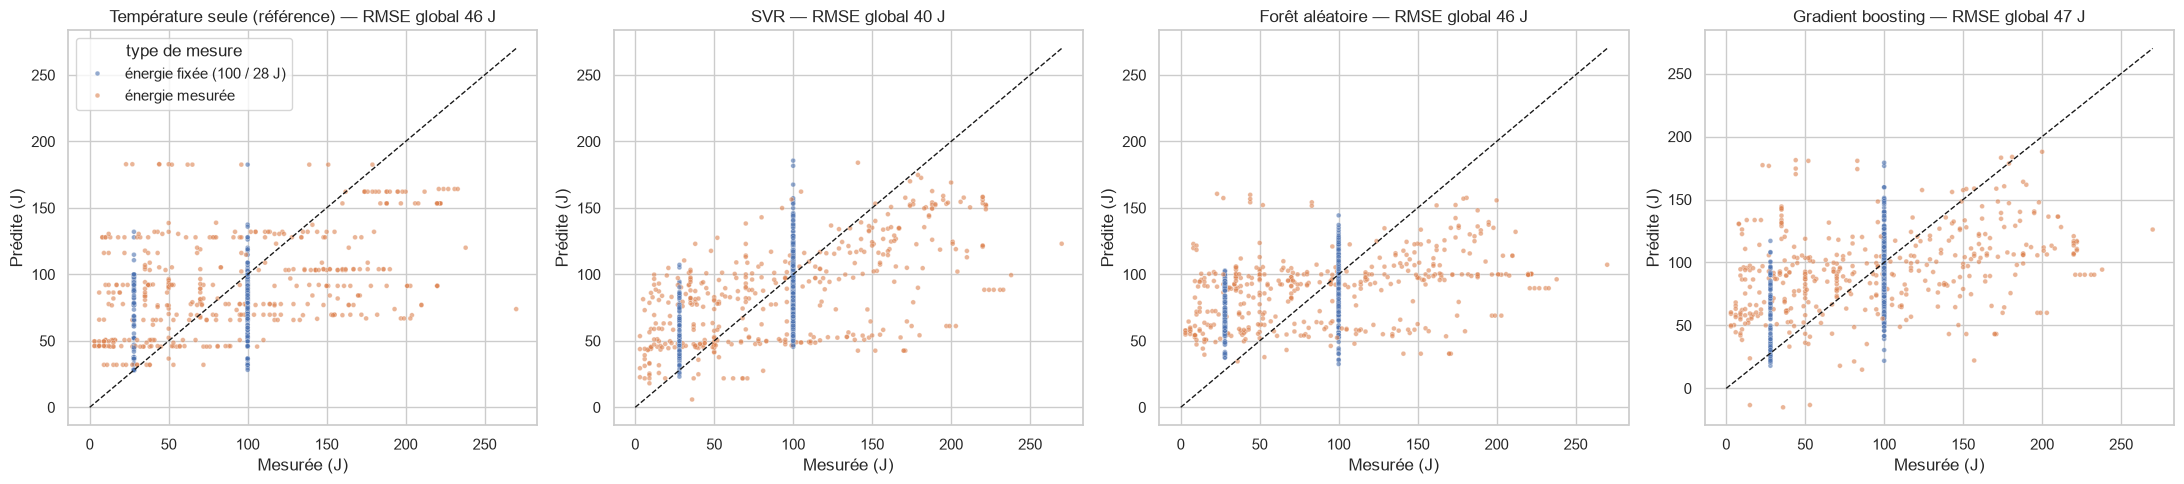

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, name in zip(axes, [TEMP_ONLY, "SVR", "Forêt aléatoire", "Gradient boosting"]):
    sns.scatterplot(x=y, y=oof[name], hue=labelled["type de mesure"], s=12, alpha=0.6, ax=ax, legend=(ax is axes[0]))
    ax.plot([0, 270], [0, 270], "k--", lw=1)
    ax.set_xlabel("Mesurée (J)"); ax.set_ylabel("Prédite (J)")
    ax.set_title(f"{name} — RMSE global {root_mean_squared_error(y, oof[name]):.0f} J")
plt.tight_layout();

## 5. Courbes de transition prédites

Pour les soudures choisies, on trace la courbe prédite par chaque modèle quand la
publication de la soudure n'a **pas** servi à l'entraînement, avec les mesures réelles.

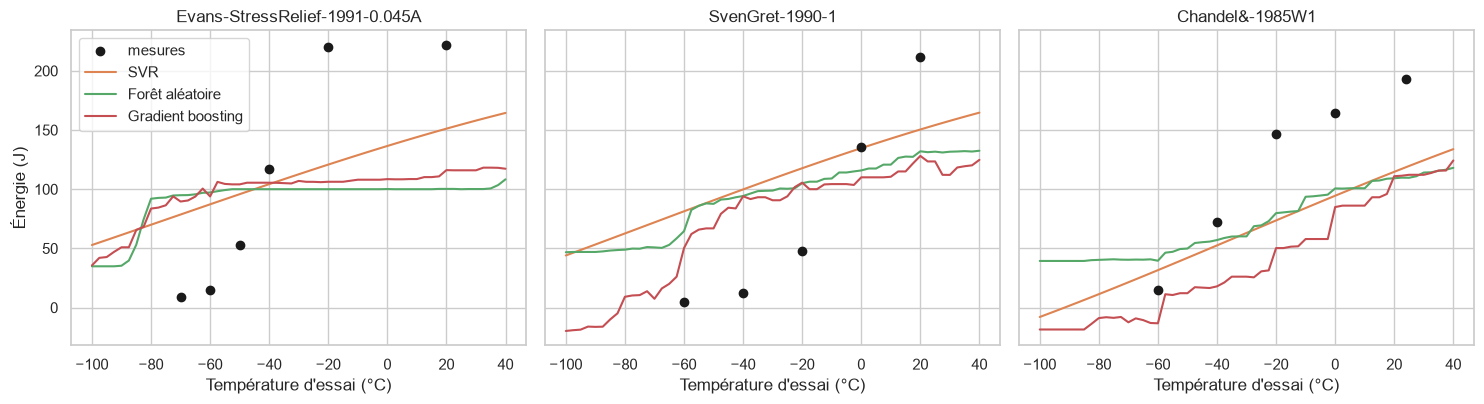

In [12]:
fig, axes = plt.subplots(1, len(curve_welds), figsize=(5 * len(curve_welds), 4.2), sharey=True)
for ax, weld in zip(np.atleast_1d(axes), curve_welds):
    measured = labelled[labelled["soudure"] == weld]
    ax.scatter(measured[TEMP], measured[TARGET], color="k", zorder=3, label="mesures")
    for name, c in [("SVR", "C1"), ("Forêt aléatoire", "C2"), ("Gradient boosting", "C3")]:
        cv = curves[(curves["soudure"] == weld) & (curves["modèle"] == name)]
        ax.plot(cv[TEMP], cv[TARGET], color=c, label=name)
    ax.set_title(weld); ax.set_xlabel("Température d'essai (°C)")
np.atleast_1d(axes)[0].set_ylabel("Énergie (J)"); np.atleast_1d(axes)[0].legend()
plt.tight_layout();

**Lecture.**
- Les deux modèles captent la tendance (l'énergie augmente avec la température), mais leurs
  courbes sont **beaucoup trop plates** : les vraies courbes passent de ~10 J à plus de
  200 J en quelques dizaines de degrés, les prédictions restent entre 50 et 150 J.
- La forêt aléatoire prédit un **plateau à 100 J** pour la soudure d'Evans, quelle que soit
  la température. C'est l'effet des lignes « énergie fixée » : pour les recettes d'Evans,
  l'entraînement contient surtout des lignes « 100 J », chacune à la température de
  transition de sa soudure, donc à des températures variées. Le modèle en déduit que ces
  soudures font 100 J à toutes les températures. Le SVR, plus lisse, est moins touché.
- Le **gradient boosting**, lui aussi fondé sur des arbres, a le même défaut (plateau vers
  100–110 J pour la soudure d'Evans). Il descend plus bas au froid, mais jusqu'à des
  énergies **négatives** (environ −20 J), physiquement impossibles : sommer les
  corrections successives de ses arbres peut sortir de la plage des valeurs vues, alors
  que la forêt fait une moyenne et y reste toujours.

### Et si on retirait les lignes « énergie fixée » ?

On refait la même validation croisée imbriquée en ne gardant que les lignes où l'énergie a
réellement été mesurée (SVR, forêt aléatoire, gradient boosting et les deux références).

In [13]:
measured = labelled[~iso].reset_index(drop=True)
X_m = preprocessing.clean(measured, extra=[TEMP])
y_m = measured[TARGET].to_numpy()
g_m = measured["publication"].to_numpy()
print(f"{len(measured)} lignes, {len(set(g_m))} publications")

rows = []
for fold, (train, test) in enumerate(outer_cv.split(X_m, y_m, g_m)):
    for name in ["Moyenne (référence)", "SVR", "Forêt aléatoire", "Gradient boosting"]:
        estimator, grid = MODELS[name]
        model = make_model(estimator)
        if grid:
            model = GridSearchCV(model, grid, cv=inner_cv, scoring="neg_root_mean_squared_error",
                                 n_jobs=-1).fit(X_m.iloc[train], y_m[train], groups=g_m[train]).best_estimator_
        else:
            model.fit(X_m.iloc[train], y_m[train])
        pred = model.predict(X_m.iloc[test])
        rows.append({"modèle": name, "RMSE": root_mean_squared_error(y_m[test], pred), "R²": r2_score(y_m[test], pred)})
    temp_only = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=0, n_jobs=-1)
    pred = temp_only.fit(X_m.iloc[train][[TEMP]], y_m[train]).predict(X_m.iloc[test][[TEMP]])
    rows.append({"modèle": TEMP_ONLY, "RMSE": root_mean_squared_error(y_m[test], pred), "R²": r2_score(y_m[test], pred)})
pd.DataFrame(rows).groupby("modèle").agg(["mean", "std"]).round(2)

405 lignes, 13 publications


RMSE           R²      
                                mean    std  mean   std
modèle                                                 
Forêt aléatoire                55.81  19.48  0.13  0.32
Gradient boosting              57.80  18.17  0.06  0.33
Moyenne (référence)            66.67   8.96 -0.28  0.21
SVR                            53.18  15.93  0.11  0.55
Température seule (référence)  57.63  15.39  0.01  0.52

Sans les lignes « énergie fixée », il ne reste que 13 publications, et les modèles ne font
pas mieux (R² ≈ 0,1, à peine au-dessus de la température seule). Retirer ces lignes ne
résout donc pas le problème : il manque surtout **des publications variées avec des courbes
de transition complètes**. On garde la formulation sur toutes les lignes.

## 6. Et le semi-supervisé ?

Au notebook 03, le self-training n'a rien apporté pour la limite d'élasticité. Pour le
Charpy, il n'est **pas applicable directement** : la température d'essai est une entrée
du modèle, et les lignes sans essai Charpy n'en ont évidemment pas. Il faudrait leur
inventer une température, puis prédire une énergie à partir de cette température inventée :
les pseudo-étiquettes n'auraient pas de lien avec une mesure réelle. On ne l'applique donc
pas ici, et on le justifiera dans le rapport.

In [14]:
scores.to_csv(RESULTS / "charpy_scores.csv", index=False)
pd.DataFrame({"weld_id": labelled["weld_id"], "publication": groups, TEMP: labelled[TEMP],
              "mesure": y, **{f"pred_{k}": v for k, v in oof.items()}}).to_csv(RESULTS / "charpy_oof.csv", index=False)
print("Résultats enregistrés dans", RESULTS)

Résultats enregistrés dans /Users/philemon/Centrale/3A/ApprAuto/Projet/soudure-ml-cs/results


## 7. Conclusion

| Modèle | RMSE (J) | R² | Commentaire |
|---|---|---|---|
| Moyenne | ~51 | −0,18 | référence |
| Température seule | ~45 | 0,03 | la recette n'est pas utilisée |
| Régression linéaire | ~67 | −1,35 | extrapole, comme pour la limite d'élasticité |
| k-NN | ~49 | −0,09 | pas mieux que la moyenne |
| **SVR** | **~40** | **0,28** | **meilleur modèle, seul nettement au-dessus de la température seule** |
| Forêt aléatoire | ~45 | 0,07 | pas mieux que la température seule, biaisée par les lignes à 100 J |
| Gradient boosting | ~47 | 0,00 | même biais que la forêt ; prédit parfois des énergies négatives |

- **Le SVR est le meilleur modèle pour la ténacité.** Sa fonction lisse résiste mieux aux
  lignes « énergie fixée » que les découpages par seuils de la forêt.
- **Le gradient boosting**, meilleur modèle pour la limite d'élasticité, ne fait pas mieux
  que la température seule ici : comme la forêt, il découpe l'espace par seuils et reproduit
  le biais des lignes « énergie fixée ».
- **Mais la prédiction reste peu fiable** : le SVR n'explique que 28 % de la variance sur des
  publications nouvelles, avec une erreur typique de 30 J, alors que l'énergie varie de 3 à
  270 J. Les courbes de transition prédites sont trop plates.
- **Pourquoi c'est plus dur que la limite d'élasticité** : la ténacité dépend fortement de
  la microstructure (ferrite aciculaire, inclusions), qui n'est presque jamais renseignée ;
  la transition ductile-fragile est très abrupte ; et seulement 26 publications ont des
  essais Charpy, dont la moitié des lignes sont des « énergies fixées ».
- **Semi-supervisé** : non applicable (pas de température d'essai pour les lignes non
  étiquetées).

**Pour le notebook 05** : la comparaison globale devra tenir compte de cette différence de
fiabilité entre les deux cibles, et les recommandations sur la ténacité devront être
formulées avec prudence.